# 01. Import and download phase

In [ ]:
!pip install pyspark kagglehub

In [ ]:
import kagglehub
import os
import shutil



In [ ]:
# dl the dataset

cache_path = kagglehub.dataset_download("darkmatternet/ultimate-pokmon-dataset-2025")
print(f"Téléchargé dans le cache Colab : {cache_path}")

# Déplacer le CSV dans le dossier principal de Colab (/content) pour qu'il soit visible
for file_name in os.listdir(cache_path):
    full_file_name = os.path.join(cache_path, file_name)

    # On s'assure de ne prendre que le fichier CSV et on le renomme proprement
    if os.path.isfile(full_file_name) and file_name.endswith('.csv'):
        shutil.copy(full_file_name, '/content/pokemon_complete_2025.csv')

print("Fichier déplacé avec succès")

Using Colab cache for faster access to the 'ultimate-pokmon-dataset-2025' dataset.
Téléchargé dans le cache Colab : /kaggle/input/ultimate-pokmon-dataset-2025
Fichier déplacé avec succès


spark session + general info about the data set


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Pokemon_EDA_Colab") \
    .getOrCreate()

pokemon_df = spark.read.csv("/content/pokemon_complete_2025.csv", header=True, inferSchema=True)
pokemon_df.show(5)

+----------+----------+--------------+----------+------+------+---------+---+------+-------+---------+----------+-----+---------------+--------+---------+---------------+---------+---------+--------------+-----+---------+---------+-----------+---------------+------------+-----------+-------+------------+--------------+-------------+-----------+--------------------+--------------------+------------+----+--------------------+--------------+-------------+---------------+---------------+--------------------+--------------------+
|pokedex_id|      name|         genus|generation|type_1|type_2|num_types| hp|attack|defense|sp_attack|sp_defense|speed|base_stat_total|height_m|weight_kg|base_experience|ability_1|ability_2|hidden_ability|color|    shape|  habitat|growth_rate|     egg_groups|is_legendary|is_mythical|is_baby|capture_rate|base_happiness|hatch_counter|gender_rate|         description|          sprite_url|is_dual_type| bmi|attack_defense_ratio|physical_total|special_total|offensive_tot

In [ ]:
print(pokemon_df.columns)

['pokedex_id', 'name', 'genus', 'generation', 'type_1', 'type_2', 'num_types', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'base_stat_total', 'height_m', 'weight_kg', 'base_experience', 'ability_1', 'ability_2', 'hidden_ability', 'color', 'shape', 'habitat', 'growth_rate', 'egg_groups', 'is_legendary', 'is_mythical', 'is_baby', 'capture_rate', 'base_happiness', 'hatch_counter', 'gender_rate', 'description', 'sprite_url', 'is_dual_type', 'bmi', 'attack_defense_ratio', 'physical_total', 'special_total', 'offensive_total', 'defensive_total', 'gender_distribution', 'stat_tier']


 # 02. Quality Assurance (Verifying "Cleanliness of data")

In [ ]:
from pyspark.sql.types import StringType
from pyspark.sql.functions import col, count, when, isnan, countDistinct


print(" Statistiques des variables catégorielles (String) ")
string_cols = [f.name for f in pokemon_df.schema.fields if isinstance(f.dataType, StringType)]
pokemon_df.select(string_cols).summary().show()

 Statistiques des variables catégorielles (String) 
+-------+----------+-----------------+----------+------+------+------------+------------+--------------+------+-----+-----------+-------------------+----------+--------------------+--------------------+--------------------+-----------------+
|summary|      name|            genus|generation|type_1|type_2|   ability_1|   ability_2|hidden_ability| color|shape|    habitat|        growth_rate|egg_groups|         description|          sprite_url| gender_distribution|        stat_tier|
+-------+----------+-----------------+----------+------+------+------------+------------+--------------+------+-----+-----------+-------------------+----------+--------------------+--------------------+--------------------+-----------------+
|  count|      1025|             1025|      1025|  1025|   526|        1025|         530|           856|  1025| 1025|        386|               1025|      1025|                1025|                1025|                1025

In [ ]:
from pyspark.sql.types import DoubleType, FloatType
from pyspark.sql.functions import col, count, when, isnan

# Assurons-nous d'avoir le total des lignes (si non défini plus haut)
total_rows = pokemon_df.count()

print("\n--- Valeurs manquantes (Comptage et Pourcentage) ---")

# Fonction pour adapter la recherche de vide au type de la colonne
def get_missing_condition(field):
    if isinstance(field.dataType, (DoubleType, FloatType)):
        return col(field.name).isNull() | isnan(col(field.name))
    else:
        return col(field.name).isNull()

# Comptage
exprs_nulls = [count(when(get_missing_condition(f), f.name)).alias(f.name) for f in pokemon_df.schema.fields]
print("Nombre de valeurs manquantes par colonne :")
pokemon_df.select(*exprs_nulls).show(vertical=True)

# Pourcentage
exprs_null_pct = [((count(when(get_missing_condition(f), f.name)) / total_rows) * 100).alias(f.name) for f in pokemon_df.schema.fields]
print("Pourcentage de valeurs manquantes par colonne (%) :")
pokemon_df.select(*exprs_null_pct).show(vertical=True)


--- Valeurs manquantes (Comptage et Pourcentage) ---
Nombre de valeurs manquantes par colonne :
-RECORD 0-------------------
 pokedex_id           | 0   
 name                 | 0   
 genus                | 0   
 generation           | 0   
 type_1               | 0   
 type_2               | 499 
 num_types            | 0   
 hp                   | 0   
 attack               | 0   
 defense              | 0   
 sp_attack            | 0   
 sp_defense           | 0   
 speed                | 0   
 base_stat_total      | 0   
 height_m             | 0   
 weight_kg            | 0   
 base_experience      | 0   
 ability_1            | 0   
 ability_2            | 495 
 hidden_ability       | 169 
 color                | 0   
 shape                | 0   
 habitat              | 639 
 growth_rate          | 0   
 egg_groups           | 0   
 is_legendary         | 0   
 is_mythical          | 0   
 is_baby              | 0   
 capture_rate         | 0   
 base_happiness       | 0   
 hat

quick note :

Pour les NA, on retrouve uniquement des valeurs manquantes pour Ability 2, hiden ability et habitat pour ce qui est des abilites 2 c'est totalement normal puisque cela est randomise, un pokemon ne recoit pas necessairement de deuxieme abilite, il en va de meme pour les attributs caches.

Pour ce qui est des habitats on manque de donnes global sur les habitats des pokemons, ils n'ont pas tous d'habitat specifique

In [ ]:
#rapide check du nombre de doublons qu'on elimine si ils sont presents
distinct_rows = pokemon_df.dropDuplicates().count()
duplicates_count = total_rows - distinct_rows
print(f"\n-Nombre total de doublons stricts : {duplicates_count}")


-Nombre total de doublons stricts : 0


In [ ]:
# renseignement sur le nombre de valeur unique par colonne, cela est tres utile notamment savoir le nombre total de pokemon, d'attaques, attaque spe, type etcc....

print("\n Nombre de valeurs uniques par colonne (Cardinalité)")
exprs_nunique = [countDistinct(c).alias(c) for c in pokemon_df.columns]
pokemon_df.select(*exprs_nunique).show(vertical=True)


 Nombre de valeurs uniques par colonne (Cardinalité)
-RECORD 0--------------------
 pokedex_id           | 1025 
 name                 | 1025 
 genus                | 715  
 generation           | 9    
 type_1               | 18   
 type_2               | 18   
 num_types            | 2    
 hp                   | 107  
 attack               | 117  
 defense              | 108  
 sp_attack            | 113  
 sp_defense           | 103  
 speed                | 119  
 base_stat_total      | 207  
 height_m             | 54   
 weight_kg            | 482  
 base_experience      | 178  
 ability_1            | 224  
 ability_2            | 131  
 hidden_ability       | 162  
 color                | 10   
 shape                | 14   
 habitat              | 9    
 growth_rate          | 6    
 egg_groups           | 65   
 is_legendary         | 2    
 is_mythical          | 2    
 is_baby              | 2    
 capture_rate         | 38   
 base_happiness       | 8    
 hatch_counter  

# 03. Ingestion et preparation

In [ ]:
from pyspark.sql.types import *
from pyspark.sql.functions import col, count, when, isnan

# Définition explicite du schéma complet
schema = StructType([
    # Identifiants et informations de base
    StructField("pokedex_id", IntegerType(), True),
    StructField("name", StringType(), True),
    StructField("genus", StringType(), True),
    StructField("generation", StringType(), True),
    StructField("type_1", StringType(), True),
    StructField("type_2", StringType(), True),
    StructField("num_types", IntegerType(), True),

    # Statistiques de combat de base
    StructField("hp", IntegerType(), True),
    StructField("attack", IntegerType(), True),
    StructField("defense", IntegerType(), True),
    StructField("sp_attack", IntegerType(), True),
    StructField("sp_defense", IntegerType(), True),
    StructField("speed", IntegerType(), True),
    StructField("base_stat_total", IntegerType(), True),

    # Caractéristiques physiques
    StructField("height_m", DoubleType(), True),
    StructField("weight_kg", DoubleType(), True),

    # Élevage et capture
    StructField("base_experience", IntegerType(), True),
    StructField("ability_1", StringType(), True),
    StructField("ability_2", StringType(), True),
    StructField("hidden_ability", StringType(), True),
    StructField("color", StringType(), True),
    StructField("shape", StringType(), True),
    StructField("habitat", StringType(), True),
    StructField("growth_rate", StringType(), True),
    StructField("egg_groups", StringType(), True),

    # Catégorisation
    StructField("is_legendary", BooleanType(), True),
    StructField("is_mythical", BooleanType(), True),
    StructField("is_baby", BooleanType(), True),

    # Mécaniques de jeu
    # ASTUCE ==> Chargé en StringType initialement pour éviter les erreurs de parsing PySpark
    StructField("capture_rate", StringType(), True),
    StructField("base_happiness", IntegerType(), True),
    StructField("hatch_counter", IntegerType(), True),
    StructField("gender_rate", DoubleType(), True),

    # Méta-données
    StructField("description", StringType(), True),
    StructField("sprite_url", StringType(), True),
    StructField("is_dual_type", BooleanType(), True),

    # Features créées (Feature Engineering)
    StructField("bmi", DoubleType(), True),
    StructField("attack_defense_ratio", DoubleType(), True),
    StructField("physical_total", IntegerType(), True),
    StructField("special_total", IntegerType(), True),
    StructField("offensive_total", IntegerType(), True),
    StructField("defensive_total", IntegerType(), True),
    StructField("gender_distribution", StringType(), True),
    StructField("stat_tier", StringType(), True)
])


# Gestion des types incorrects
# Parmi les types incorrects de la base, on retrouve le capture rate qui contenait parfois des anomalies textuelles.
pokemon_df = pokemon_df.withColumn("capture_rate", col("capture_rate").cast("integer"))

#  Gestion des valeurs manquantes et doublons
# L'absence d'un type_2 est une donnée valide (Pokémon monotype), on remplace Null par "Aucun".
pokemon_df = pokemon_df.fillna({"type_2": "Aucun"}).dropDuplicates()

# Vérification finale
print("Aperçu des données nettoyées :")
pokemon_df.select("name", "type_1", "type_2", "capture_rate", "base_stat_total").show(5)

Aperçu des données nettoyées :
+---------+--------+-------+------------+---------------+
|     name|  type_1| type_2|capture_rate|base_stat_total|
+---------+--------+-------+------------+---------------+
|  golduck|   water|  Aucun|          75|            500|
|electrode|electric|  Aucun|          60|            490|
|teddiursa|  normal|  Aucun|         120|            330|
| slowpoke|   water|psychic|         190|            315|
|   swalot|  poison|  Aucun|          75|            467|
+---------+--------+-------+------------+---------------+
only showing top 5 rows


In [ ]:
from pyspark.storagelevel import StorageLevel

print(" Optimisation Mémoire")
# On stocke le dataset nettoyé 100% dans la RAM des workers tjrs pour des questions d'otpimization des ressources
pokemon_df.persist(StorageLevel.MEMORY_ONLY)

# Spark étant fainéant (Lazy Evaluation), le persist ne se déclenche que si
# on fait une Action. On force donc la mise en cache avec un count() :
total_rows = pokemon_df.count()
print(f"Dataset de {total_rows} lignes mis en cache (MEMORY_ONLY). Toutes les analyses suivantes seront instantanées.")

 Optimisation Mémoire
Dataset de 1025 lignes mis en cache (MEMORY_ONLY). Toutes les analyses suivantes seront instantanées.


# 04. Exploratory data analysis (EDA), general info  about the data set and visualisation
   #### - Exploratory data analysis
   #### - Univariate
   #### - Bivariate
   #### - Multivariate

-------------------------------------------------------------------

## Exploratory data analysis


In [ ]:
from pyspark.sql.functions import desc, avg

# Question 1 : Top 10 Pokémon les plus puissants
# Répond à l'exigence : "Quels sont les top 10 produits les plus vendus ?" (Adapté aux stats)
top_10_pokemon = pokemon_df.orderBy(desc("base_stat_total")).limit(10)

print("Top 10 Pokémon par statistiques totales :")
top_10_pokemon.select("name", "base_stat_total", "is_legendary").show()


# Question 2 : Moyenne de points de vie (HP) par génération
# Répond à l'exigence : "Quel est le panier moyen ?" (Adapté à la moyenne des stats)
hp_by_gen = pokemon_df.groupBy("generation") \
                    .agg(avg("hp").alias("moyenne_hp")) \
                    .orderBy("generation")

print("Moyenne des HP par génération :")
hp_by_gen.show()


# Question 3 : Répartition par type principal
# Répond à l'exigence : "Quels pays génèrent le plus de revenus ?" (Adapté à la répartition des types)
count_by_type = pokemon_df.groupBy("type_1").count().orderBy(desc("count"))

print("Nombre de Pokémon par type principal :")
count_by_type.show(5)

Top 10 Pokémon par statistiques totales :
+----------------+---------------+------------+
|            name|base_stat_total|is_legendary|
+----------------+---------------+------------+
|          arceus|            720|       false|
|       eternatus|            690|        true|
|          dialga|            680|        true|
|           lugia|            680|        true|
|          mewtwo|            680|        true|
|          zekrom|            680|        true|
|        solgaleo|            680|        true|
|giratina-altered|            680|        true|
|        reshiram|            680|        true|
|         xerneas|            680|        true|
+----------------+---------------+------------+

Moyenne des HP par génération :
+----------+-----------------+
|generation|       moyenne_hp|
+----------+-----------------+
|         I|64.21192052980132|
|        II|            70.98|
|       III|65.66666666666667|
|        IV|73.10280373831776|
|        IX|77.39166666666667|
|    

-------------------------------------------------------------------

## Univariate


In [ ]:
#  Import des packages necessaires pour la visualisation + bridge et optmisation de la memoire ( bonne gestion des donnees)

import matplotlib.pyplot as plt
import seaborn as sns

# bridge PYSPARK -> PANDAS
# On ne charge en mémoire locale que les 5 colonnes utiles pour ces graphiques ( gestion des donnees )

pdf_univ = pokemon_df.select("base_stat_total", "is_legendary", "type_1", "type_2", "stat_tier").toPandas()

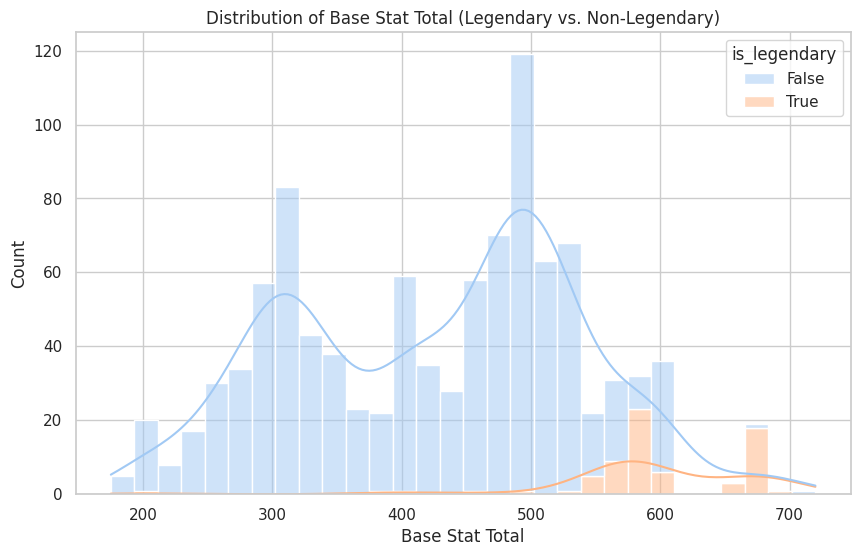

In [ ]:
# Graph 1 : Distribution of base stat total
sns.set_theme(style="whitegrid", palette="pastel")
plt.figure(figsize=(10, 6))
sns.histplot(data=pdf_univ, x='base_stat_total', bins=30, kde=True, hue='is_legendary', multiple="stack")
plt.title('Distribution of Base Stat Total (Legendary vs. Non-Legendary)')
plt.xlabel('Base Stat Total')
plt.ylabel('Count')
plt.show()

quick note : La distribution des statistiques de base des Pokémon standards est dites "bimodale" (deux pics majeurs autour de 300 et 500), cela correspond souvent aux stades d'évolution.
Les Pokémon Légendaires se distinguent de par leur stats de base qui semblent overpower comparees aux pokemon "normaux.  on a une distribution resserrée à l'extrême droite du graphique, confirmant leur statut d'élite

Frequency o

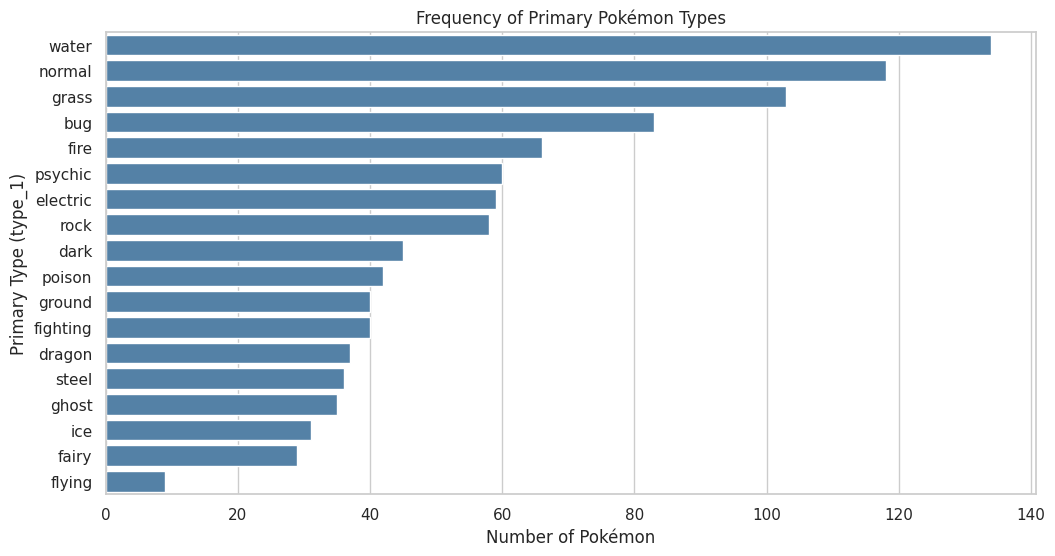

In [ ]:
# Graph 2 : Frequency of Primary Pokémon Types
plt.figure(figsize=(12, 6))
type_order = pdf_univ['type_1'].value_counts().index
sns.countplot(data=pdf_univ, y='type_1', order=type_order, color='steelblue')
plt.title('Frequency of Primary Pokémon Types')
plt.xlabel('Number of Pokémon')
plt.ylabel('Primary Type (type_1)')
plt.show()

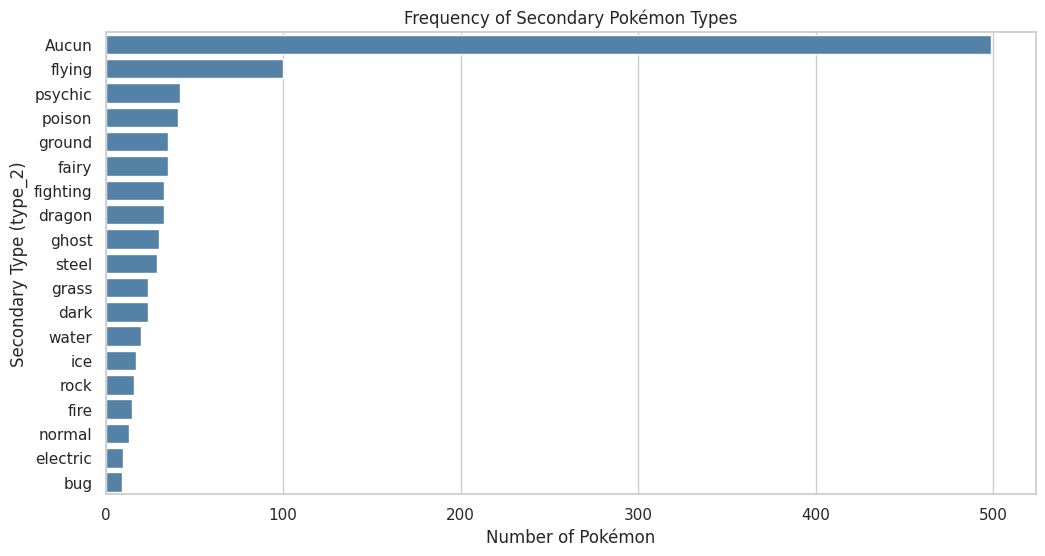

In [ ]:
# Graph 3 : Frequency of Secondary Pokémon Types
plt.figure(figsize=(12, 6))
type_order_2 = pdf_univ['type_2'].value_counts().index
sns.countplot(data=pdf_univ, y='type_2', order=type_order_2, color='steelblue')
plt.title('Frequency of Secondary Pokémon Types')
plt.xlabel('Number of Pokémon')
plt.ylabel('Secondary Type (type_2)')
plt.show()

quick note : L'écosystème pokemon est dominé par les types Eau et Normal en type principal.( imo surement un choix des devs de gestion de la license) Concernant le type secondaire, une écrasante majorité de Pokémon n'en possède pas, ce qui est assez normal, pour rappel les seconds types sont relativement rares dans l'univers du jeu  (catégorie "Aucun"). Lorsqu'un double type existe, le type Vol est de loin le plus commun, agissant souvent comme un attribut complémentaire (ex: Normal/Vol, Insecte/Vol).

/tmp/ipykernel_4024/2095354252.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=pdf_univ, x='stat_tier', order=pdf_univ['stat_tier'].value_counts().index, palette='Set2')


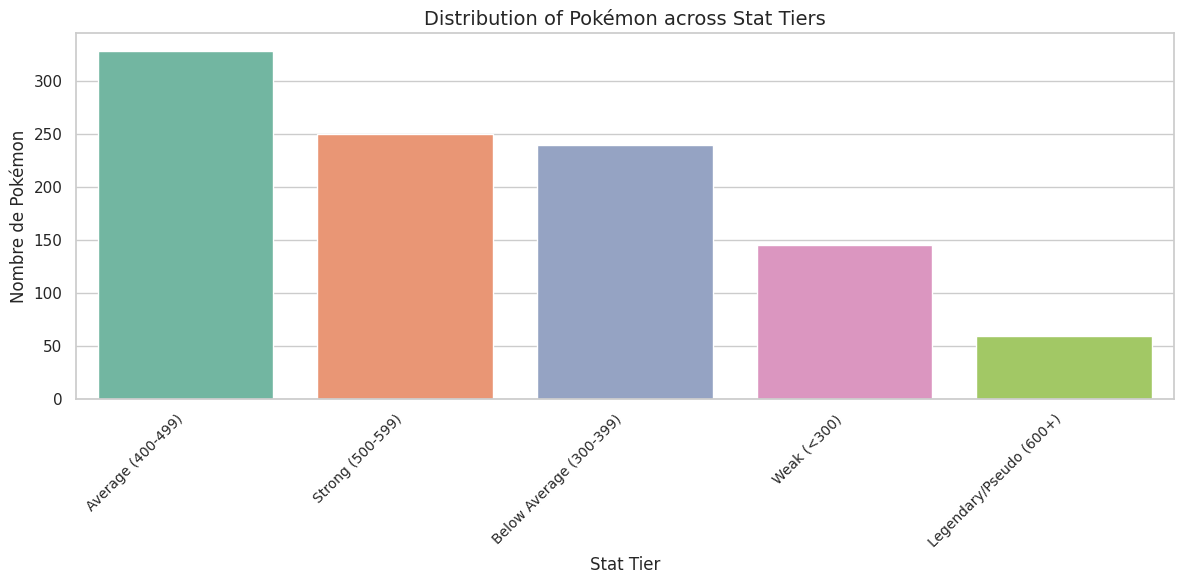

In [ ]:
# Graph 4 : Distribution of Pokémon across Stat Tiers
plt.figure(figsize=(12, 6))

sns.countplot(data=pdf_univ, x='stat_tier', order=pdf_univ['stat_tier'].value_counts().index, palette='Set2')

plt.title('Distribution of Pokémon across Stat Tiers', fontsize=14)
plt.xlabel('Stat Tier', fontsize=12)
plt.ylabel('Nombre de Pokémon', fontsize=12)

plt.xticks(rotation=45, ha='right', fontsize=10)

plt.tight_layout()
plt.show()

quick note : la majorité des pokemons se situent dans les tiers "Average" (400-499) et "Strong" (500-599). Le jeu est conçu pour que la plupart des Pokémon finaux atteignent ce niveau moyen, rendant les catégories extrêmes (très faibles ou légendaires) beaucoup plus rares.

-------------------------------------------------------------------

## Bivariate


Quelque de transformation, ajout 2 3 variables et conversion pour la visualisation

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.functions import col, when

In [ ]:

# A. Création de la colonne specialist_type
pokemon_df = pokemon_df.withColumn(
    'specialist_type',
    when(col('physical_total') > col('special_total'), 'Physical Specialist')
    .when(col('special_total') > col('physical_total'), 'Special Specialist')
    .otherwise('Balanced')
)

# B. Conversion du capture_rate en pourcentage
pokemon_df = pokemon_df.withColumn(
    'capture_rate_pct',
    (col('capture_rate') / 255) * 100
)

# C. Création de la catégorie Legendary/Mythical
pokemon_df = pokemon_df.withColumn(
    'legendary_mythical',
    when(col('is_legendary') == True, 'Legendary/Mythical')
    .otherwise('Common/Normal')
)


In [ ]:
# brige pour la gestion de memoire on utilise que ce que l'on a besoin comme pour le univarie
pdf_biv = pokemon_df.select(
    'generation', 'base_stat_total', 'is_legendary', 'weight_kg', 'speed',
    'stat_tier', 'physical_total', 'special_total', 'type_1',
    'specialist_type', 'capture_rate_pct', 'legendary_mythical'
).toPandas()

### visualisation

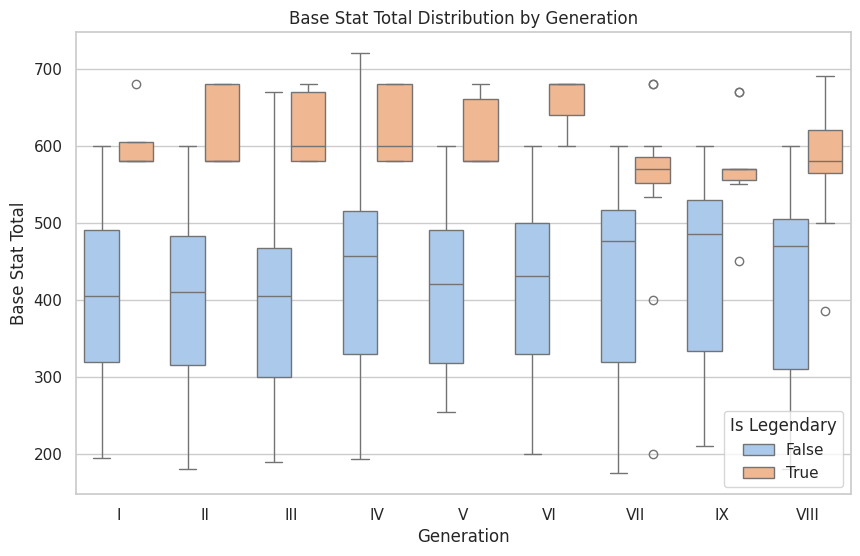

In [ ]:
# Graph 1 : Power creep
plt.figure(figsize=(10, 6))
sns.boxplot(data=pdf_biv, x='generation', y='base_stat_total', hue='is_legendary')
plt.title('Base Stat Total Distribution by Generation')
plt.xlabel('Generation')
plt.ylabel('Base Stat Total')
plt.legend(title='Is Legendary', loc='lower right')
plt.show()

Quick note  : Contrairement aux idées reçues , il n'y a pas de "Power Creep" (inflation des statistiques) massif au fil du temps et au cours des generations pour les Pokémon standards : la médiane reste remarquablement stable autour de 400-450 points à travers les neuf générations. En revanche, la puissance des Légendaires fluctue énormément selon la génération.

ce qui montre que les devs equilibrent relativement bien les pokemons et l'univers qui va avec. ( surement un algo de random forest permettant d'equilibrer les stats)

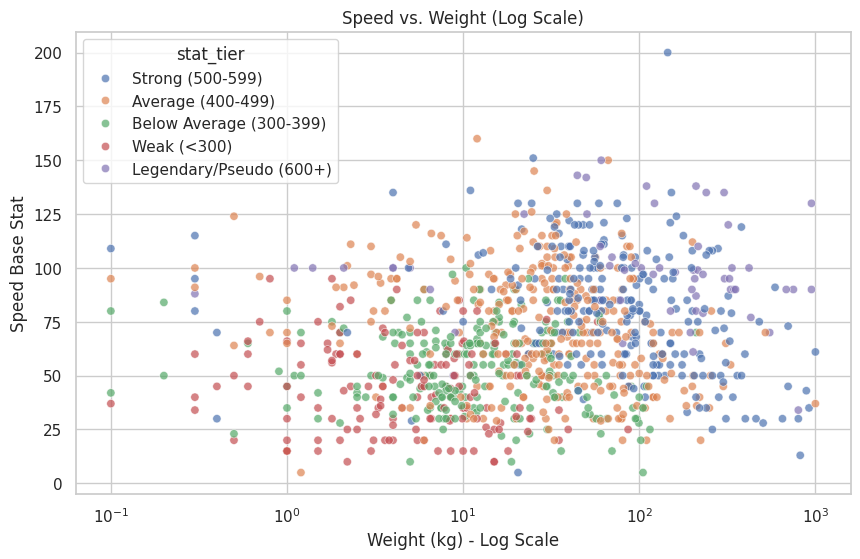

In [ ]:
# Graph 2 : Speed vs. Weight
plt.figure(figsize=(10, 6))
sns.scatterplot(data=pdf_biv, x='weight_kg', y='speed', hue='stat_tier', alpha=0.7)
plt.xscale('log')
plt.title('Speed vs. Weight (Log Scale)')
plt.xlabel('Weight (kg) - Log Scale')
plt.ylabel('Speed Base Stat')
plt.show()

quick note : Le poids ne dicte pas strictement la vitesse. Bien qu'une grande partie des Pokémon les plus lourds soient lents, le graphique montre une très forte dispersion. Il existe de nombreux Pokémon très légers mais lents, et quelques exceptions massives dotées d'une excellente vitesse. Si vous jouez beaucoup aux jeux pokemons certains, il est clair que cet aspect n'est pas develope certains pokemon extrement lourd sont assez rapide selon leurs attaques c'est le cas de tortank par exemple

/tmp/ipykernel_4024/2010737349.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


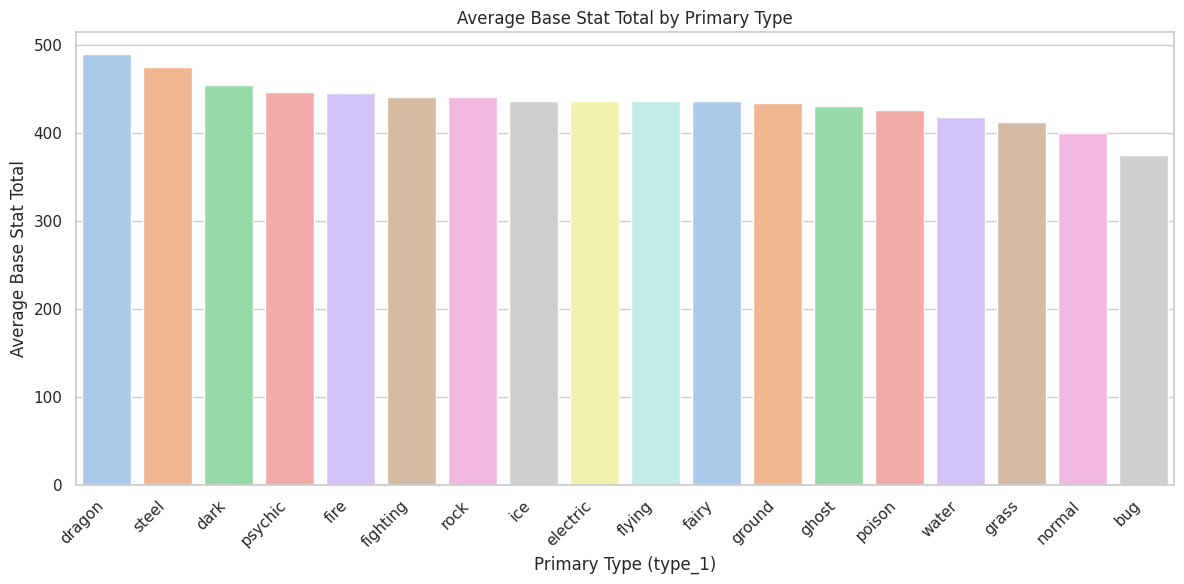

In [ ]:
# Graph 4 : Average Base Stat by Type
plt.figure(figsize=(12, 6))
type_mean_order = pdf_biv.groupby('type_1')['base_stat_total'].mean().sort_values(ascending=False).index
sns.barplot(
    data=pdf_biv,
    x='type_1',
    y='base_stat_total',
    order=type_mean_order,
    errorbar=None,
    palette='pastel'
)
plt.title('Average Base Stat Total by Primary Type')
plt.xlabel('Primary Type (type_1)')
plt.ylabel('Average Base Stat Total')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

quick note : Les types Dragon et Acier dominent largement le classement des moyennes, ce qui s'aligne avec leur rôle thématique de types rares ou de "fin de jeu". À l'inverse, le type Insecte est statistiquement le plus faible du jeu, conçu historiquement pour le tout début de l'aventure. En effet, les taux de captures de ces pokemons ( dragon, acier) tend a etre bien plus faibles, par ailleurs leur taux d'apparition egalement. ( exemple dans epee et bouclier trioxhydre a un taux d'apparition de 2% :D)

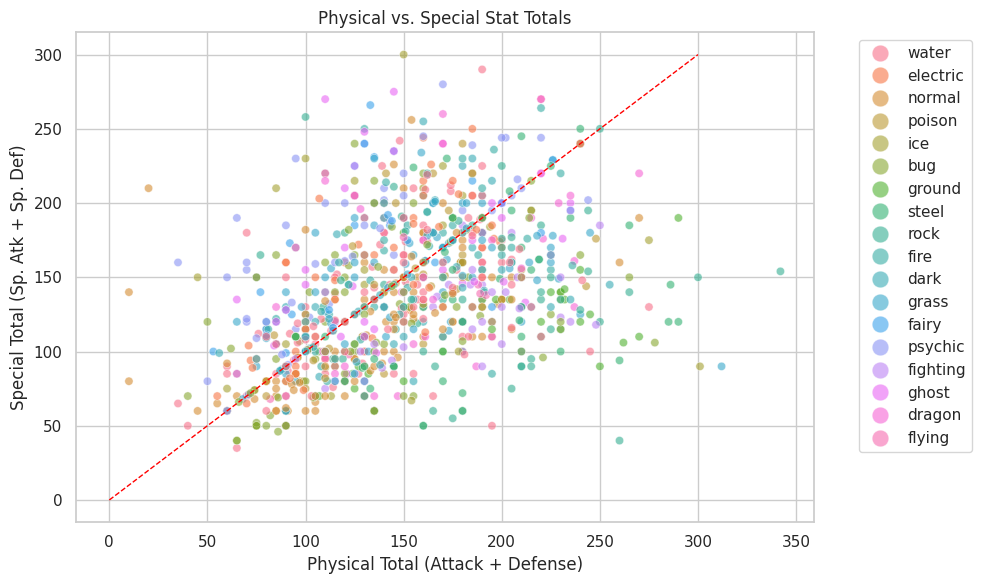

In [ ]:
# Graph 3 : Physical vs. Special Specialists
plt.figure(figsize=(10, 6))
sns.scatterplot(data=pdf_biv, x='physical_total', y='special_total', hue='type_1', alpha=0.6)
plt.plot([0, 300], [0, 300], color='red', linestyle='--', linewidth=1)
plt.title('Physical vs. Special Stat Totals')
plt.xlabel('Physical Total (Attack + Defense)')
plt.ylabel('Special Total (Sp. Atk + Sp. Def)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=2)
plt.tight_layout()
plt.show()

quick note : La ligne diagonale rouge sépare parfaitement les deux styles de combat. L'histogramme confirme que le jeu a un biais vers le combat physique : il y a environ 150 spécialistes physiques de plus que de spécialistes spéciaux. Les profils parfaitement "équilibrés" sont une minorité.


/tmp/ipykernel_4024/553880491.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=pdf_biv, x='specialist_type', order=['Physical Specialist', 'Special Specialist', 'Balanced'], palette='Set2')


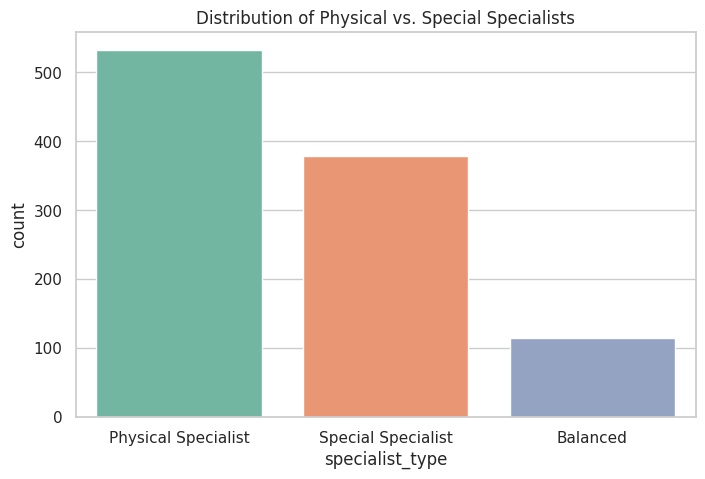

In [ ]:
#Graph 5 : Physical vs Special Specialists Count
plt.figure(figsize=(8, 5))
sns.countplot(data=pdf_biv, x='specialist_type', order=['Physical Specialist', 'Special Specialist', 'Balanced'], palette='Set2')
plt.title('Distribution of Physical vs. Special Specialists')
plt.show()

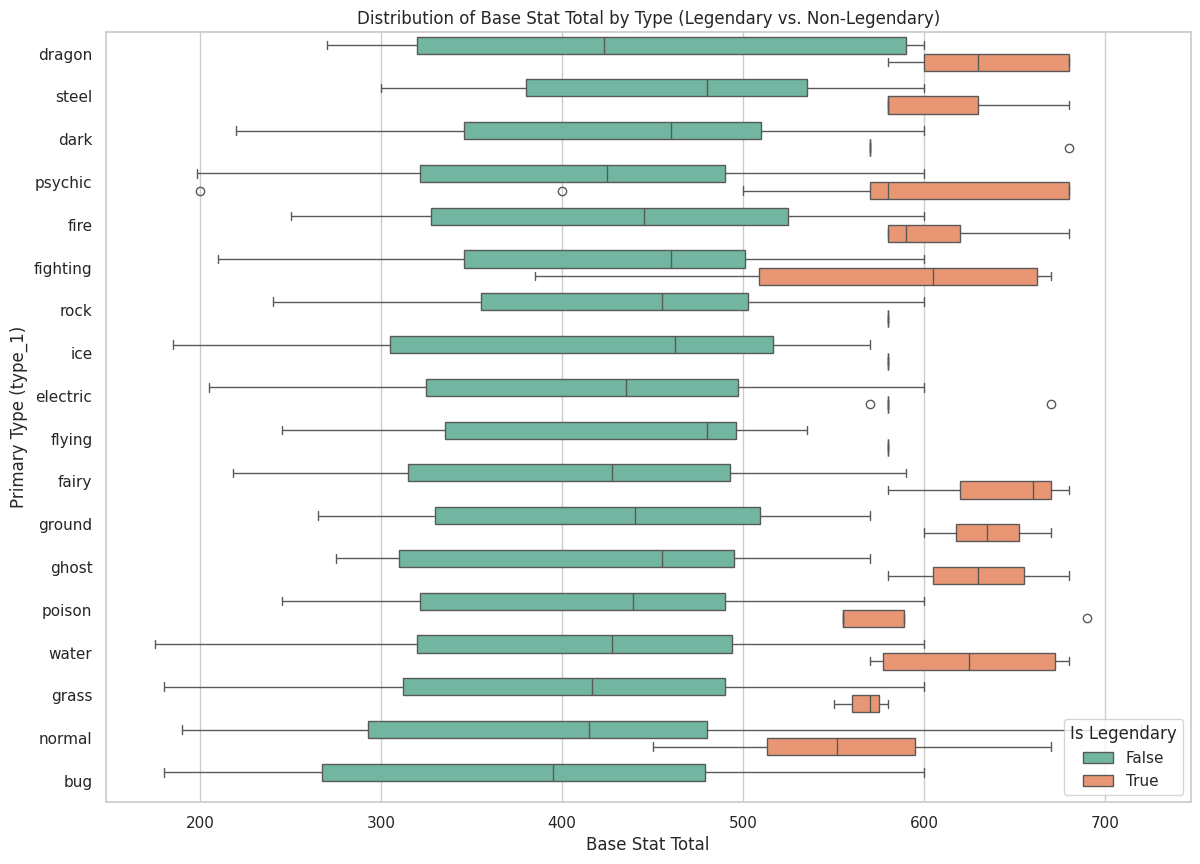

In [ ]:
# Graph 6 : Boxplot Stat Total by Type
plt.figure(figsize=(14, 10))
sns.boxplot(
    data=pdf_biv,
    x='base_stat_total',
    y='type_1',
    order=type_mean_order,
    hue='is_legendary',
    dodge=True,
    palette='Set2'
)
plt.title('Distribution of Base Stat Total by Type (Legendary vs. Non-Legendary)')
plt.xlabel('Base Stat Total')
plt.ylabel('Primary Type (type_1)')
plt.legend(title='Is Legendary', loc='lower right')
plt.show()

quick note : le graph illustre la hiérarchie intrinsèque des types. Les types Dragon et Acier possèdent les médianes les plus élevées chez les Pokémon standards ( comme vu precedement), justifiant leur réputation de types "puissants" ou de fin de jeu. L'ajout de la dimension "Légendaire" (en orange) montre que, peu importe le type assigné, le statut de Légendaire propulse systématiquement le pokemon  dans l'élite statistique (autour de 600-700 points), on une scission nette avec les legendaires confirmant leur statut over-cheate raison pour lesquelle dans le modele ml ils sont retirees.

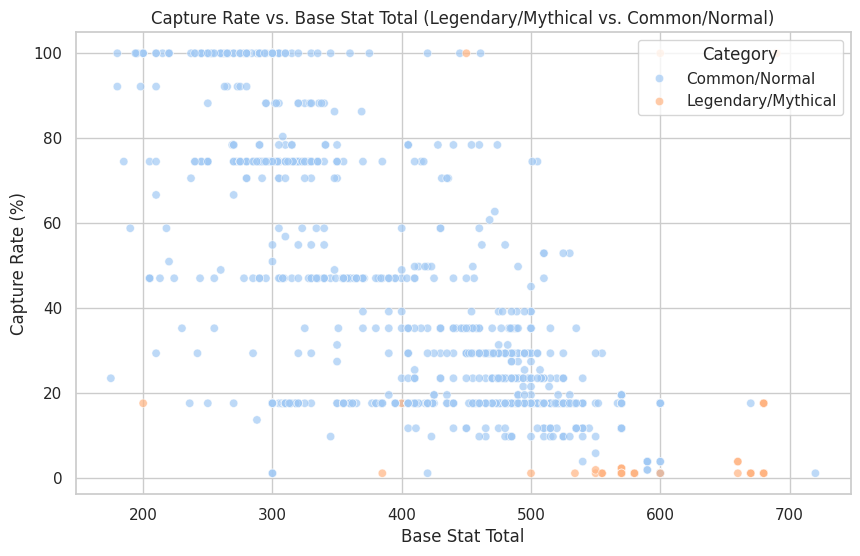

In [ ]:
# Graph 7 : Capture Rate vs Base Stat Total
plt.figure(figsize=(10, 6))
sns.scatterplot(data=pdf_biv, x='base_stat_total', y='capture_rate_pct', hue='legendary_mythical', alpha=0.7)
plt.title('Capture Rate vs. Base Stat Total (Legendary/Mythical vs. Common/Normal)')
plt.xlabel('Base Stat Total')
plt.ylabel('Capture Rate (%)')
plt.legend(title='Category', loc='upper right')
plt.show()

quick note : On a une corrélation négative forte et non linéaire qui se dégage : la difficulté de capture agit comme un mécanisme d'équilibrage direct face à la puissance brute. Globalement plus un pokemon a de bonne stat plus il est dur capturer ( mechanisme d'equilibrage)
 Les Pokémon Légendaires et Mythiques (en orange) forment un cluster exclusif et intentionnel en bas à droite du graphique, combinant des statistiques maximales avec un taux de capture punitif et bas(souvent inférieur à 5%).

/tmp/ipykernel_4024/3784475732.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=top_standard, x='base_stat_total', y='name', palette='pastel')
/tmp/ipykernel_4024/3784475732.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=top_legendary, x='base_stat_total', y='name', palette='pastel')
/tmp/ipykernel_4024/3784475732.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2], data=top_mythical, x='base_stat_total', y='name', palette='pastel')


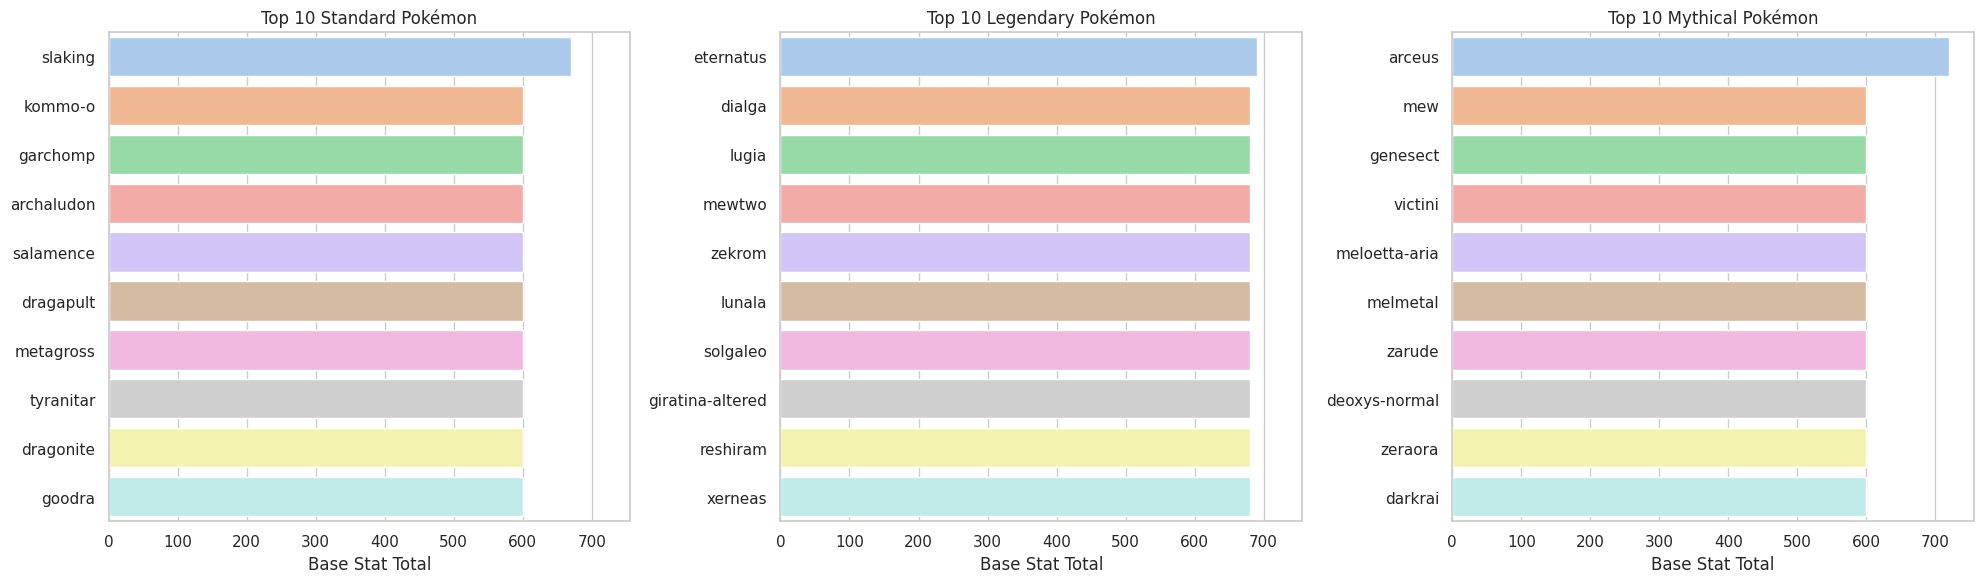

In [ ]:
# mise en place de filtres pour chaque categorie de pokemon (Top 10)
summary_columns = ['name', 'type_1', 'type_2', 'base_stat_total', 'generation']

# Top 10 Standard
top_standard = pokemon_df.filter((col('is_legendary') == False) & (col('is_mythical') == False)) \
                         .orderBy(col('base_stat_total').desc()) \
                         .limit(10).toPandas()

# Top 10 Legendary
top_legendary = pokemon_df.filter((col('is_legendary') == True) & (col('is_mythical') == False)) \
                          .orderBy(col('base_stat_total').desc()) \
                          .limit(10).toPandas()

# Top 10 Mythical
top_mythical = pokemon_df.filter(col('is_mythical') == True) \
                         .orderBy(col('base_stat_total').desc()) \
                         .limit(10).toPandas()


# VISUALISATION

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True)
sns.set_theme(style="whitegrid")

sns.barplot(ax=axes[0], data=top_standard, x='base_stat_total', y='name', palette='pastel')
axes[0].set_title('Top 10 Standard Pokémon')
axes[0].set_xlabel('Base Stat Total')
axes[0].set_ylabel('')

sns.barplot(ax=axes[1], data=top_legendary, x='base_stat_total', y='name', palette='pastel')
axes[1].set_title('Top 10 Legendary Pokémon')
axes[1].set_xlabel('Base Stat Total')
axes[1].set_ylabel('')

sns.barplot(ax=axes[2], data=top_mythical, x='base_stat_total', y='name', palette='pastel')
axes[2].set_title('Top 10 Mythical Pokémon')
axes[2].set_xlabel('Base Stat Total')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

quick note : Ce ranking  met en évidence le concept de "Pseudo-Légendaires" dans la catégorie Standard (des Pokémon comme Dracolosse ou Tyranocif qui viennent s'aligner sur un plafond strict de 600 points). Du côté des Légendaires et Mythiques, les standards sont repoussés (atteignant 720 points pour Arceus). On note que le modèle de conception du jeu tend à uniformiser les statistiques des pokemons d'élite avec les meilleurs stats  autour de paliers très précis (600, 680). A noter que Arceus est considere comme le legendaire parmis les legendaires et est le seul pokemon a pouvant apprendre des attaques de n'importe quel type, c'est le pokemon le plus puissant/ cheat des jeux et de l'univers pokemon en general.

-------------------------------------------------------------------

## Multivariate

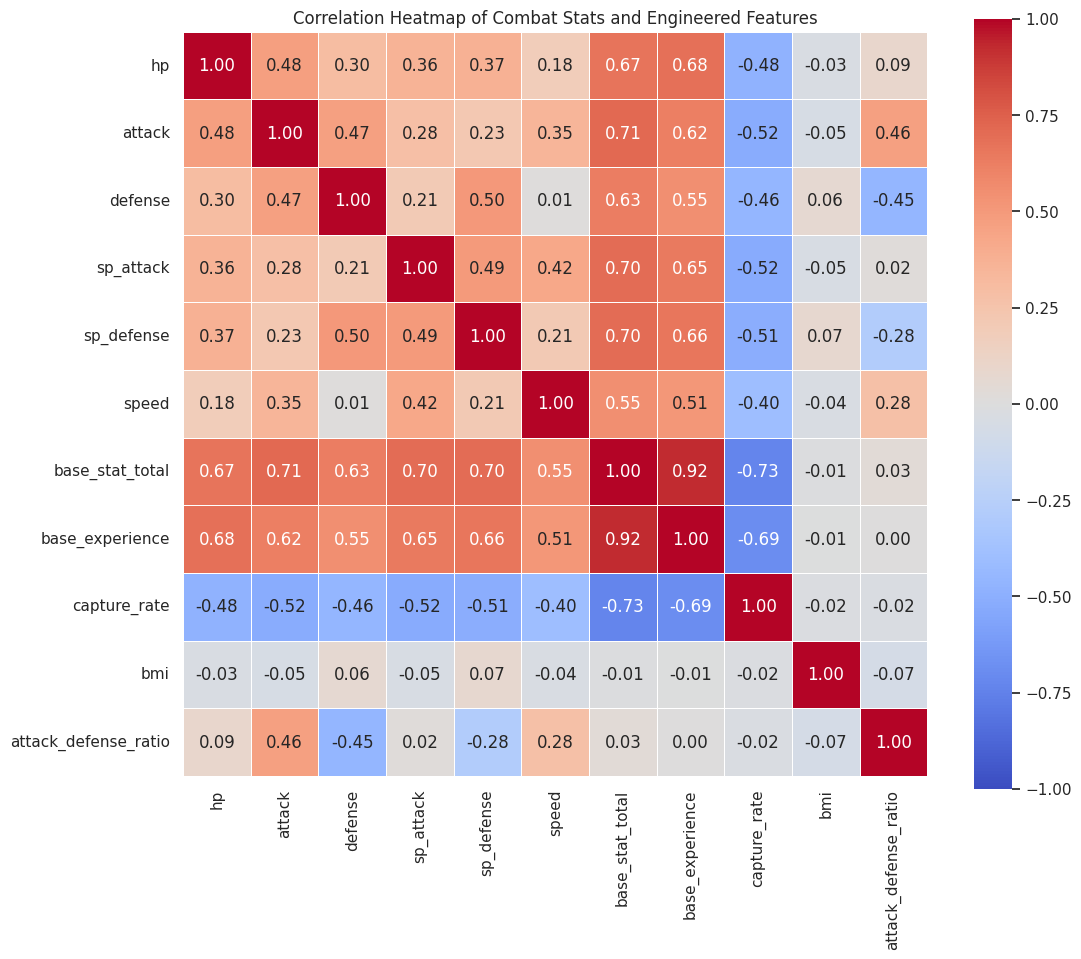

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.sql.functions import col

# CALCUL DISTRIBUÉ DE LA MATRICE DE CORRÉLATION (PySpark ML)

stats_col_combat = [
    'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed',
    'base_stat_total', 'base_experience', 'capture_rate',
    'bmi', 'attack_defense_ratio'
]

# A. Sécurité : S'assurer que toutes les colonnes cibles sont bien numériques (Double)
# (Le capture_rate a déjà été converti à l'étape précédente, on cast tout pour être sûr)
df_numeric = pokemon_df.select([col(c).cast("double") for c in stats_col_combat])

# B. Spark ML demande de regrouper toutes ces colonnes en un seul "Vecteur"
# On utilise handleInvalid="skip" pour ignorer automatiquement les lignes avec des valeurs nulles
assembler = VectorAssembler(inputCols=stats_col_combat, outputCol="features", handleInvalid="skip")
df_vector = assembler.transform(df_numeric).select("features")

# C. Calcul de la matrice de corrélation (Pearson par défaut) via Spark
matrix_row = Correlation.corr(df_vector, "features").head()
corr_matrix_array = matrix_row[0].toArray() # On extrait le tableau numpy

# D. On replace le résultat dans un DataFrame Pandas pour l'affichage
correlation_matrix = pd.DataFrame(corr_matrix_array, index=stats_col_combat, columns=stats_col_combat)


# Visualisation

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=.5
)
plt.title('Correlation Heatmap of Combat Stats and Engineered Features')
plt.show()

quick note : La matrice valide mathématiquement les dynamiques du jeu. La statistique globale (base_stat_total) est presque parfaitement corrélée à l'expérience cédée en combat (base_experience, 0.92) et fortement inversement corrélée au taux de capture (capture_rate, -0.73). Fait intéressant sur l'équilibrage (Game Design) : la Vitesse (speed) n'a presque aucune corrélation avec la Défense (0.01) ou le ratio Attaque/Défense, prouvant que les développeurs évitent intentionnellement de créer des pokemons qui soient simultanément les plus rapides et les plus résistantes.

Analyse Multivariée : Pairplot des Spécialistes


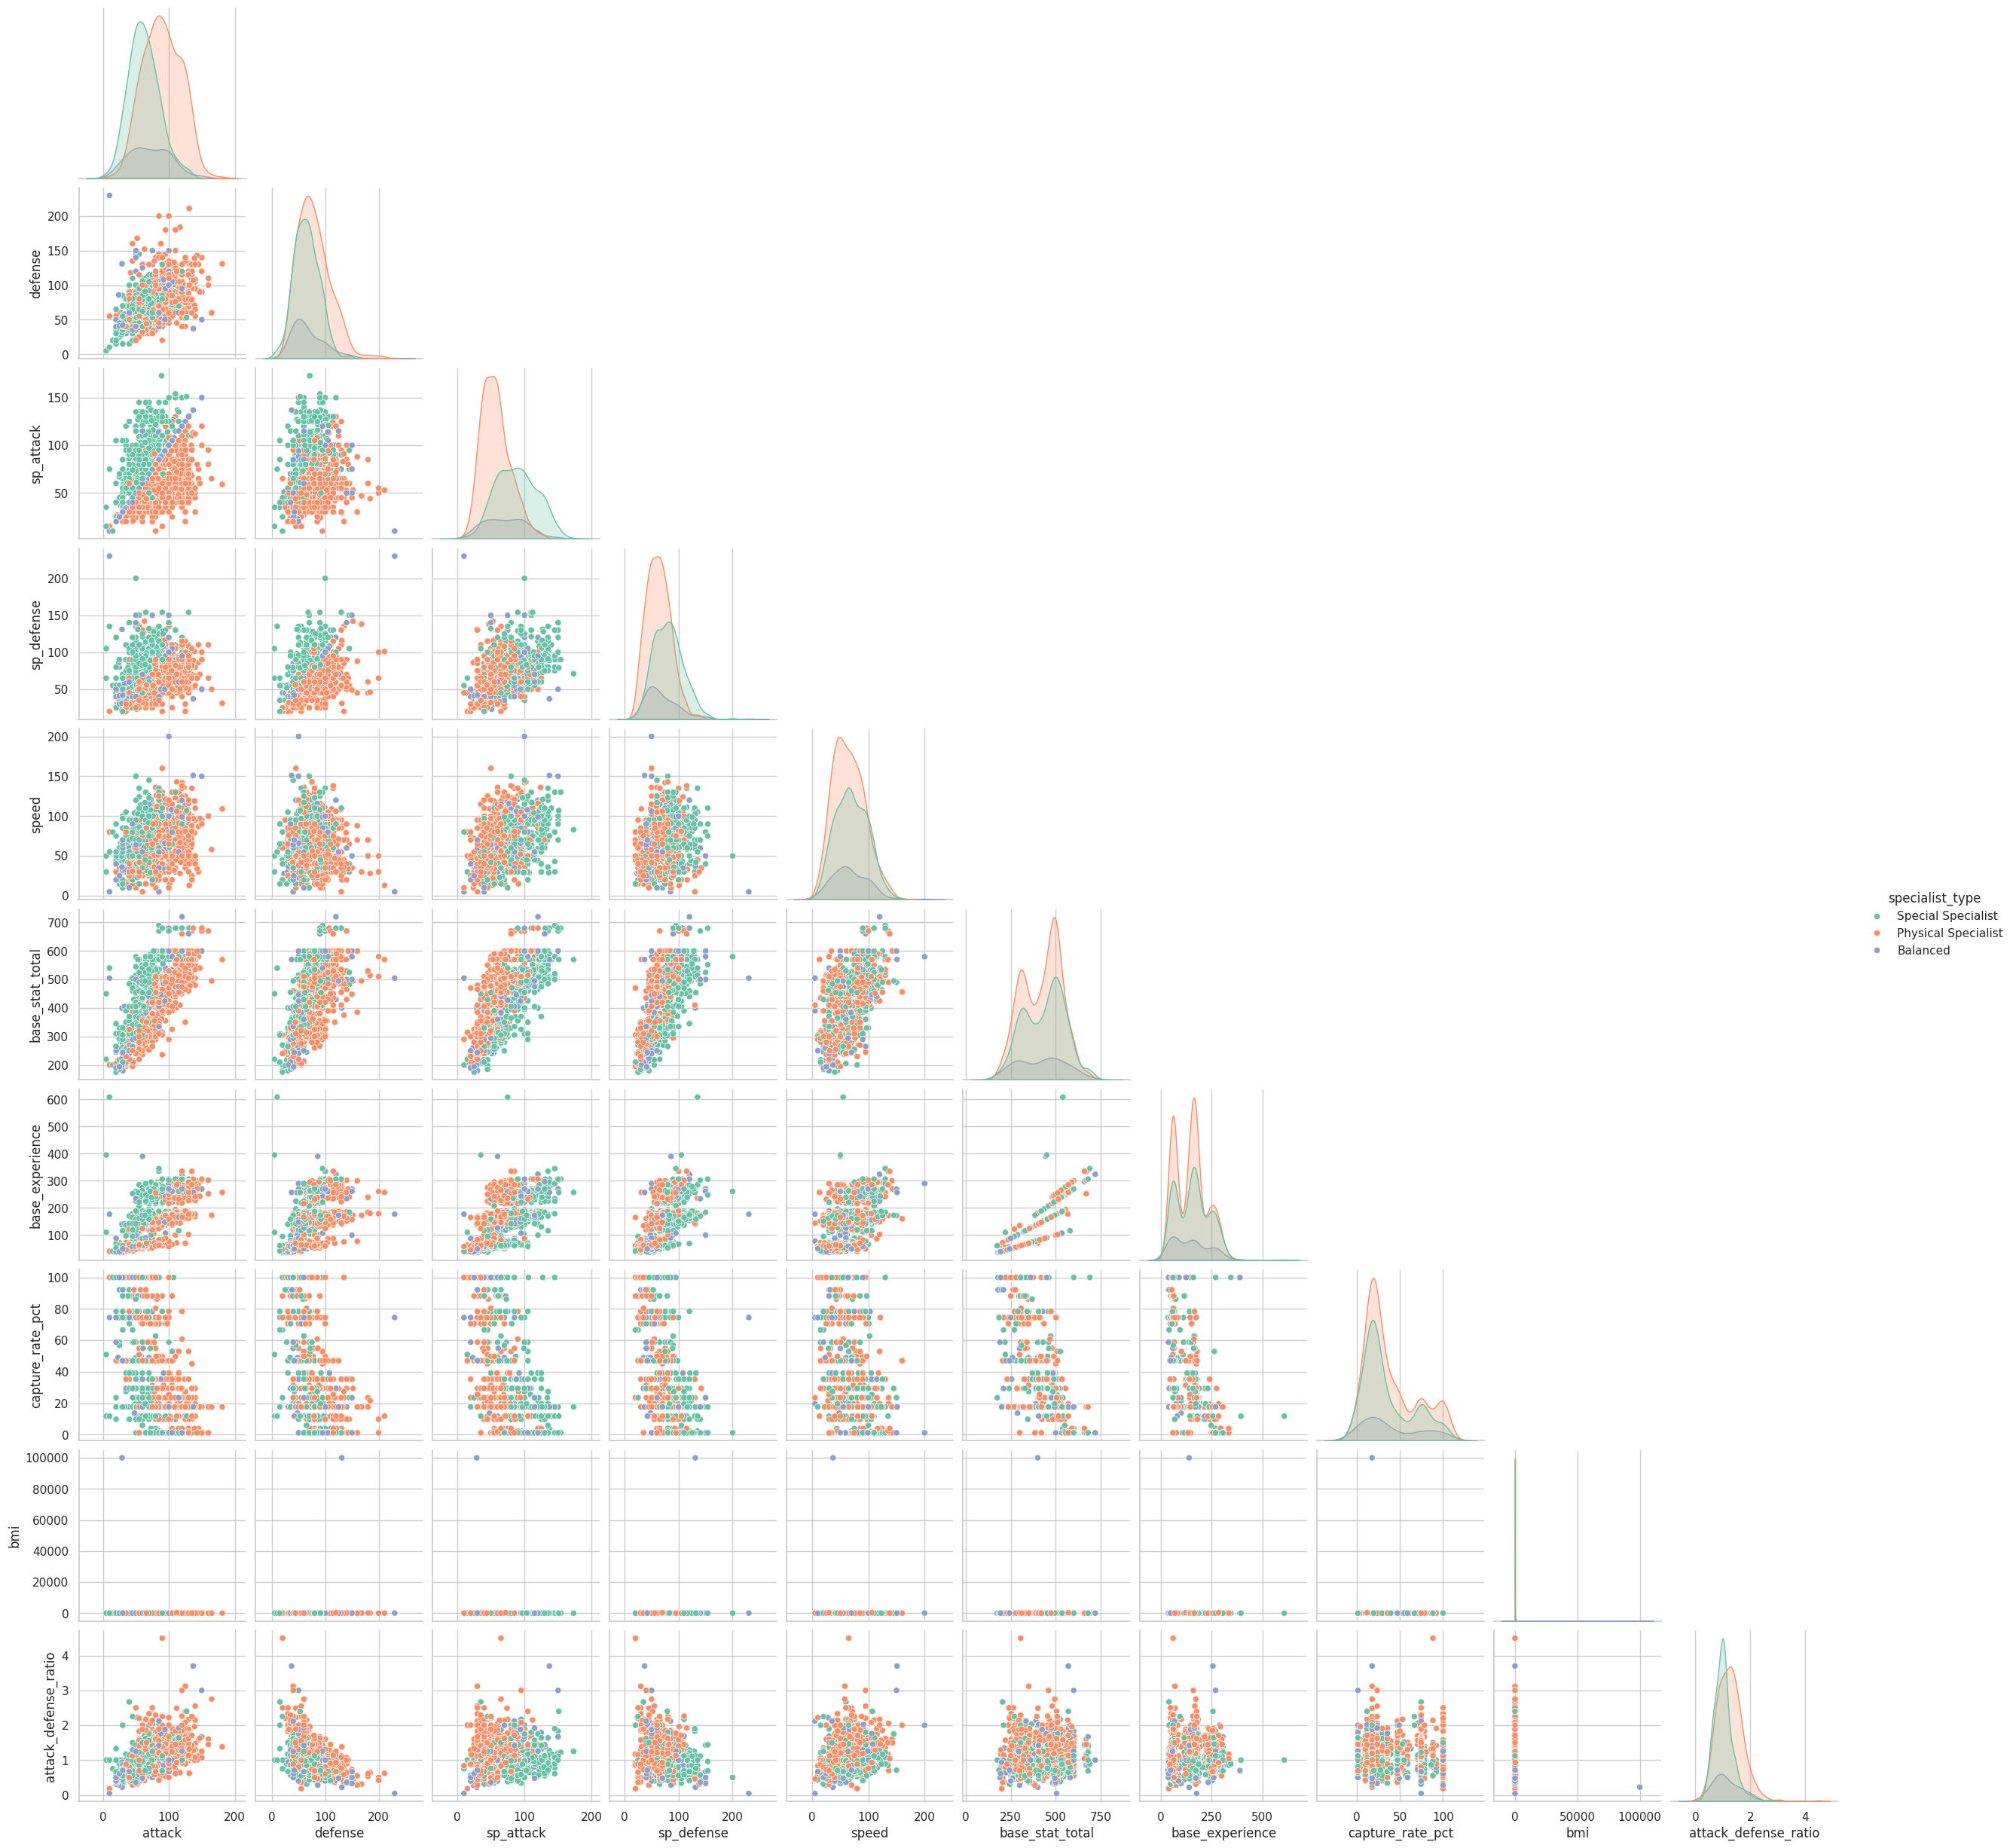

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from pyspark.sql.functions import col, when

print("Analyse Multivariée : Pairplot des Spécialistes")

# 1. Le Pont PySpark -> Pandas

col_to_plot = [
    'specialist_type', 'type_1', 'type_2',
    'attack', 'defense', 'sp_attack', 'sp_defense', 'speed',
    'base_stat_total', 'base_experience', 'capture_rate_pct',
    'bmi', 'attack_defense_ratio'
]

# On sélectionne uniquement ces colonnes et on supprime les NA pour éviter les crashs de Seaborn
pdf_pairplot = pokemon_df.select(*col_to_plot).na.drop().toPandas()

# 2. Visualisation Seaborn
sns.pairplot(
    pdf_pairplot,
    hue='specialist_type',
    palette='Set2',
    diag_kind='kde',
    corner=True
)
plt.show()

quick note : Ce graphique croisé illustre parfaitement la dichotomie des styles de combat. On observe une séparation nette des groupes (vert et orange) sur les croisements liés à l'Attaque et la Défense (physique vs spécial). En revanche, sur les statistiques "neutres" comme les Points de Vie (HP) ou la Vitesse (Speed), les courbes de densité se superposent presque parfaitement. Cela démontre que le Game Design ne sacrifie pas la vitalité ou la rapidité d'un Pokémon sous prétexte de sa spécialisation offensive : un "Mage" a autant de chances d'être rapide qu'un "Chevalier

# 05. Advanced transformation

quick note

cette section est a but illustratif est sert a demontrer la puissance pyspark et les types de jointures que l'on peut faire avec


In [ ]:
from pyspark.sql.window import Window
from pyspark.sql.functions import col, desc, rank, max, min, avg, count, broadcast

# 1. Window Function : Classement par génération

windowSpec = Window.partitionBy("generation").orderBy(desc("base_stat_total"))
df_ranked = pokemon_df.withColumn("rank_in_generation", rank().over(windowSpec))


# Affichage du t3 pokemon pour chaque gen

print("Top 3 Pokémon de chaque génération :")
df_ranked.filter(col("rank_in_generation") <= 3) \
         .select("generation", "rank_in_generation", "name", "base_stat_total") \
         .show(10)

# 2. Aggregation avancée : Profil complet par Type 1

type_profile = pokemon_df.groupBy("type_1").agg(
    avg("attack").alias("avg_attack"),
    max("defense").alias("max_defense"),
    min("speed").alias("min_speed"),
    count("pokedex_id").alias("total_pokemon")
)

print("\nProfil statistique avancé par type :")
type_profile.show(5)

# 3. JOINTURE COMPLEXE OPTIMISÉE (Broadcast Hash Join)

# type_profile étant une petite table du dataset (18 lignes), on utilise la fonction broadcast() ==> pour rappel on utilise quand dataframe < 10 mb
# le but etant du broadcast d'ecrire en memoire et d'optimiser la gestion des ressources,
# Force ==> Spark à envoyer la table dans la RAM de tous les nœuds, évitant un "Shuffle" coûteux et gourmand en ressources calculatoires
df_joined = pokemon_df.join(broadcast(type_profile), on="type_1", how="left") # jointure a gauche table principale pokemon_df

print("\nRésultat de la jointure optimisée :")
df_joined.select("name", "type_1", "attack", "avg_attack").show(5)


# 4. PREUVE DE L'OPTIMISATION (Pour l'évaluation)

print("\nPlan d'exécution de la jointure (Vérifiez la présence de 'BroadcastHashJoin') :")
df_joined.explain() # le .explain est a but illustratif ici

Top 3 Pokémon de chaque génération :
+----------+------------------+---------+---------------+
|generation|rank_in_generation|     name|base_stat_total|
+----------+------------------+---------+---------------+
|         I|                 1|   mewtwo|            680|
|         I|                 2|dragonite|            600|
|         I|                 2|      mew|            600|
|        II|                 1|    ho-oh|            680|
|        II|                 1|    lugia|            680|
|        II|                 3|   celebi|            600|
|        II|                 3|tyranitar|            600|
|       III|                 1| rayquaza|            680|
|       III|                 2|  slaking|            670|
|       III|                 2|  groudon|            670|
+----------+------------------+---------+---------------+
only showing top 10 rows

Profil statistique avancé par type :
+------+-----------------+-----------+---------+-------------+
|type_1|       avg_attack

Quick notes about transformation :

Window Function : L'utilisation de Window.partitionBy() permet de créer un palmarès local (par génération) sans écraser la granularité de la donnée, ce qu'un simple groupBy ne permettrait pas de faire.

Jointure Complexe : La jointure (left join) entre le dataset granulé (un Pokémon) et le dataset aggrégé (profil par type) permet un enrichissement des features. Cela offre la possibilité de créer des métriques dérivées, comme évaluer si un Pokémon est au-dessus ou en dessous de la moyenne de sa catégorie.

 Transformations Avancées : Corrélations par Catégorie 


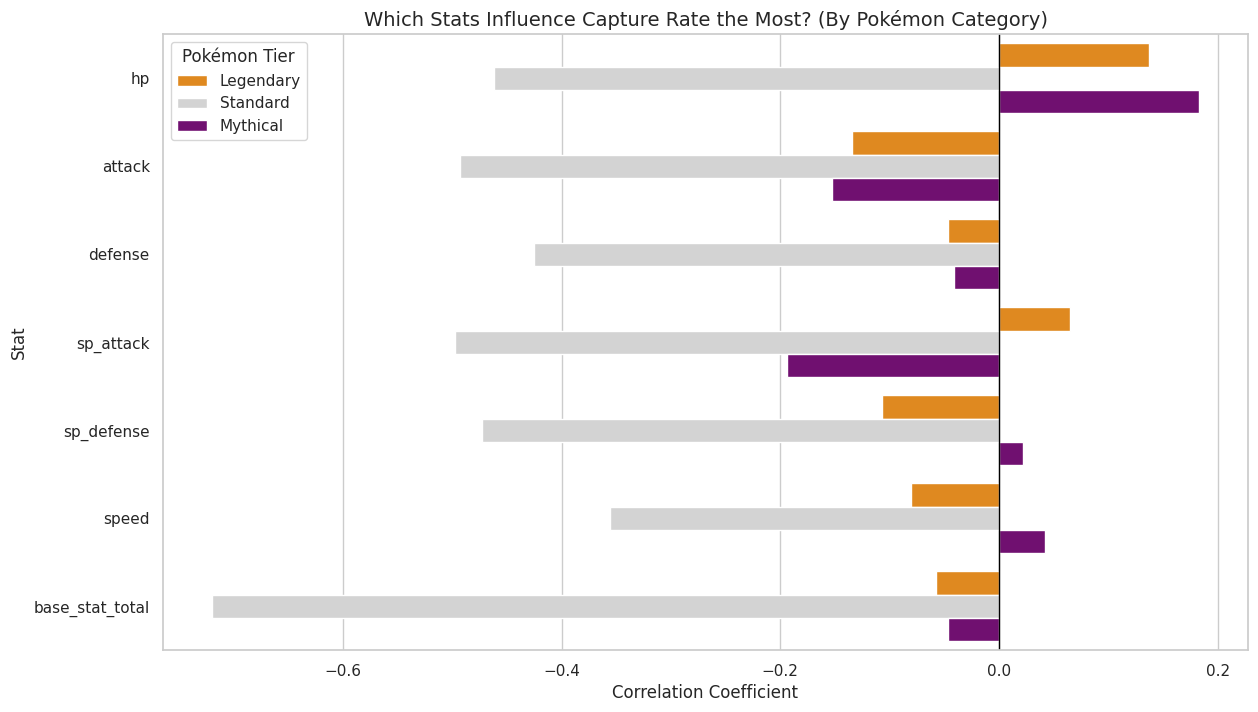

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.functions import col, when, corr as spark_corr

print(" Transformations Avancées : Corrélations par Catégorie ")



# Calcul distribué des corrélations (PySpark)
stats_to_test = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'base_stat_total']

# On crée dynamiquement la liste des opérations statistiques à faire
agg_exprs = [spark_corr(col(stat), col('capture_rate_pct')).alias(stat) for stat in stats_to_test]

# PySpark calcule tout simultanément sur le cluster
corr_grouped_spark = pokemon_df.groupBy('classification').agg(*agg_exprs)


# 2. Pont vers Pandas et reformatage pour Seaborn
pdf_corr_wide = corr_grouped_spark.toPandas()

# On utilise 'melt' pour passer du format large au format long (requis pour le hue de Seaborn)
corr_df = pdf_corr_wide.melt(
    id_vars='classification',
    var_name='Stat',
    value_name='Correlation with Capture Rate'
)

# 3. Visualisation
plt.figure(figsize=(14, 8))

# setting couleurs
palette_colors = {'Standard': 'lightgray', 'Legendary': 'darkorange', 'Mythical': 'purple'}

sns.barplot(
    data=corr_df,
    x='Correlation with Capture Rate',
    y='Stat',
    hue='classification',
    palette=palette_colors
)

plt.title('Which Stats Influence Capture Rate the Most? (By Pokémon Category)', fontsize=14)
plt.axvline(0, color='black', linewidth=1)
plt.legend(title='Pokémon Tier')
plt.xlabel('Correlation Coefficient')
plt.show()

quick note : Ce graphique révèle une mécanique d'équilibrage fondamentale du jeu. Pour les Pokémon Standards (barres grises), on observe une forte corrélation négative universelle : plus leurs statistiques (notamment le base_stat_total) sont élevées, plus leur taux de capture baisse logiquement.
Cependant, pour les Légendaires et Mythiques (orange et violet), ces corrélations s'effondrent et s'approchent de zéro. Cela confirme que leur difficulté de capture n'est pas calculée par une formule dynamique basée sur leur puissance, mais qu'elle est "hardcodée" (fixée arbitrairement très bas, généralement à 3) pour garantir un combat difficile, peu importe les variations statistiques de la créature.

# 06. Machine learning

#### Objectif de cette section :
Jusqu'a present, notre analyse s'est concentree sur la comprehension descriptive des donnees. Dans cette derniere etape, nous allons exploiter la puissance de l'apprentissage automatique (Machine Learning) avec PySpark MLlib pour extraire des connaissances latentes et resoudre un probleme d'optimisation concret.


L'Apprentissage Non-Supervise (Clustering et PCA) : Au lieu de nous fier a la categorisation des types ( eau,feu, dragon fee,etc..), nous allons laisser un algorithme K-Means decouvrir et regrouper par lui-meme les veritables "Archetypes de Combat" (Tanks, Attaquants rapides, etc.) en analysant la variance des statistiques de base, dans le but ensuite de creer la meilleure equipe possible (team building).

Le Teambuilding : Un des grands objectifs et centre d'interet dans les jeux pokemons resident dans la confrontation par equipe de 6 pokemons par dresseur aussi appele combat / vs. A cet egard, l'objectif final de cette section vise a partir du data set et des donnees compilees de trouver la meilleur equipe theorique en se basant sur les statistiques pures. Meme si la realite differe fortement, notamment de part le fait que meme certains pokemon consideraient comme faible sur le plan statistique peuvent etre une aubaine en combat contre dresseur de part leurs capacites passives ou attributs caches. ( ex : pour les connaissseurs des attaques comme sleep/sommeil ou rugissement sont par exemple extrement fortes et utilises en combat et peuvent etre appliquees a des pokemons faibles).

Par ailleurs dans les jeux pokemons toutes les generations et pokemons ne sont pas forcements tous disponibles.

Optimisation sous contraintes:

En combinant nos clusters avec les fonctions de partitionnement de Spark, nous allons developper un algorithme capable de generer theoriquement la meilleure equipe possible (maximisation de la puissance sous contrainte de diversite totale des types)

step 1 : Preparation des donnees pour le Clustering
step 2 : Entrainement du modele K-Means 
step 3 : Reduction en 2 dimensions pour la visualisation 
step 4 : Preparation des donnees pour le Clustering
step 5 : Entrainement du modele K-Means 
step 6 : Reduction en 2 dimensions pour la visualisation 


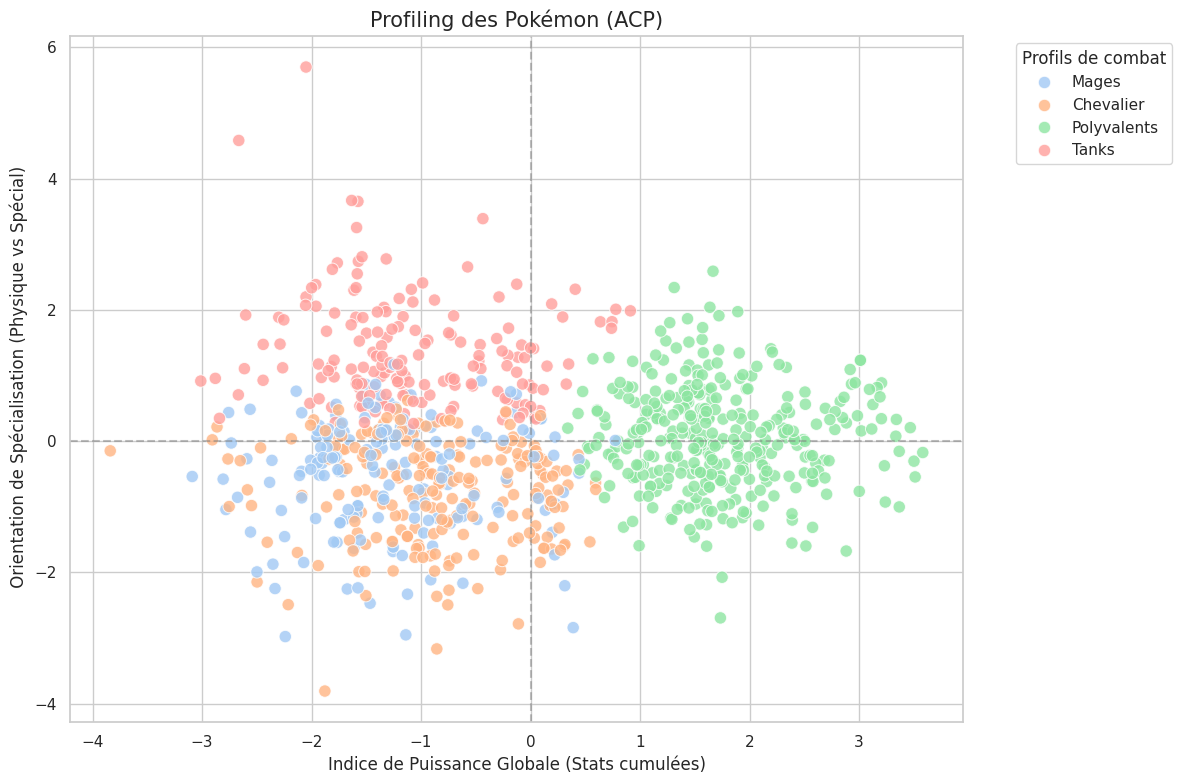

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans
from pyspark.sql.functions import col, when, avg

print("step 1 : Preparation des donnees pour le Clustering")

# 1. On filtre pour ne garder que les Pokemon Standards purs
df_standard = pokemon_df.filter(col("classification") == "Standard")

# 2. Selection des features de combat
combat_features = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
df_ml = df_standard.select(['name', 'type_1', 'type_2', 'base_stat_total'] + combat_features).na.drop()

# 3. Assemblage en vecteur ==> obligatoire en pyspark on ne peeut donner un tableau a l'algo
assembler = VectorAssembler(inputCols=combat_features, outputCol="raw_features")
df_vectorized = assembler.transform(df_ml)

# 4. Standardisation (Crucial pour le K-Means afin qu'aucune stat ne domine les autres)
scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_vectorized)
df_scaled = scaler_model.transform(df_vectorized)

print("step 2 : Entrainement du modele K-Means ")

# 5. Clustering K-Means (On demande a l'algorithme de trouver 4 profils/archetypes)
kmeans = KMeans(featuresCol="scaled_features", predictionCol="cluster", k=4, seed=42)
kmeans_model = kmeans.fit(df_scaled)
df_clustered = kmeans_model.transform(df_scaled)

print("step 3 : Reduction en 2 dimensions pour la visualisation ")

# 6. PCA pour passer de 6 stats a 2 axes (X et Y) pour le graphique
pca = PCA(k=2, inputCol="scaled_features", outputCol="pca_features")
pca_model = pca.fit(df_clustered)
df_pca = pca_model.transform(df_clustered)

# 7. Extraction des coordonnees PCA pour Pandas
from pyspark.ml.functions import vector_to_array
df_viz_spark = df_pca.withColumn("pca_x", vector_to_array("pca_features")[0]) \
                     .withColumn("pca_y", vector_to_array("pca_features")[1])

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans
from pyspark.sql.functions import col, when, avg

print("step 4 : Preparation des donnees pour le Clustering")

# 1. On filtre pour ne garder que les Pokemon Standards purs
df_standard = pokemon_df.filter(col("classification") == "Standard")

# 2. Selection des features de combat
combat_features = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
df_ml = df_standard.select(['name', 'type_1', 'type_2', 'base_stat_total'] + combat_features).na.drop()

# 3. Assemblage en vecteur
assembler = VectorAssembler(inputCols=combat_features, outputCol="raw_features")
df_vectorized = assembler.transform(df_ml)

# 4. Standardisation (Crucial pour le K-Means afin qu'aucune stat ne domine les autres)
scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_vectorized)
df_scaled = scaler_model.transform(df_vectorized)

print("step 5 : Entrainement du modele K-Means ")

# 5. Clustering K-Means (On demande a l'algorithme de trouver 4 profils/archetypes)
kmeans = KMeans(featuresCol="scaled_features", predictionCol="cluster", k=4, seed=42)
kmeans_model = kmeans.fit(df_scaled)
df_clustered = kmeans_model.transform(df_scaled)

print("step 6 : Reduction en 2 dimensions pour la visualisation ")

# 6. PCA pour passer de 6 stats a 2 axes (X et Y) pour le graphique
pca = PCA(k=2, inputCol="scaled_features", outputCol="pca_features")
pca_model = pca.fit(df_clustered)
df_pca = pca_model.transform(df_clustered)

# 7. Extraction des coordonnees PCA pour Pandas
from pyspark.ml.functions import vector_to_array
df_viz_spark = df_pca.withColumn("pca_x", vector_to_array("pca_features")[0]) \
                     .withColumn("pca_y", vector_to_array("pca_features")[1])

# PROFILING : On calcule les moyennes par cluster pour les nommer
df_clustered = df_viz_spark.withColumn(
    "cluster_name",
    when(col("cluster") == 0, "Tanks")  # Tank / profil defensif ( HP et Défense très élevés, Vitesse lente) "
    .when(col("cluster") == 1, "Chevalier") # chevalier  / Attaquants Physiques( Attaque et Vitesse élevées.)
    .when(col("cluster") == 2, "Polyvalents") # Polyvalents (Stats basses et équilibrées)
    .otherwise("Mages") # Mages / Spécialistes Spéciaux (Attaque Spéciale et Vitesse élevées, peu de PV.)
)

pdf_clusters = df_clustered.select("name", "type_1", "cluster_name", "pca_x", "pca_y").toPandas()

# 8. Visualisation des profils
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=pdf_clusters,
    x="pca_x",
    y="pca_y",
    hue="cluster_name",
    palette="pastel",
    alpha=0.8,
    s=80
)

# Titres explicites des composantes
plt.title("Profiling des Pokémon (ACP)", fontsize=15)
plt.xlabel("Indice de Puissance Globale (Stats cumulées)", fontsize=12)
plt.ylabel(" Orientation de Spécialisation (Physique vs Spécial)", fontsize=12)

plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.legend(title="Profils de combat", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number

print(" Construction de l'Equipe Standard Ultime (Optimisation Algorithmique)")

# 1. Pour garantir la diversite, nous faisons un classement interne par type principal
# Window : On regroupe par type_1, et on trie du plus puissant au moins puissant
window_diversity = Window.partitionBy("type_1").orderBy(col("base_stat_total").desc())

# 2. On attribue un rang a chaque Pokemon au sein de son propre type
df_ranked_by_type = df_clustered.withColumn("rank_in_type", row_number().over(window_diversity))

# 3. La Selection :
# - On ne prend que le meilleur absolu de chaque type (rank_in_type == 1) ==> meilleur eau,feu, glace ...
# - On trie ces champions par puissance globale
# - On garde les 6 meilleurs pour former l'equipe
ultimate_team = df_ranked_by_type.filter(col("rank_in_type") == 1) \
                                 .orderBy(col("base_stat_total").desc()) \
                                 .limit(6)

print("Equipe theorique parfaite de 6 Pokemon Standards sachant diversite de Type Maximisee) :")
ultimate_team.select("name", "type_1", "type_2", "base_stat_total", "cluster").show()  # P

# Validation des statistiques moyennes de l'equipe
ultimate_team.agg({"base_stat_total": "avg"}).withColumnRenamed("avg(base_stat_total)", "Puissance Moyenne de l'Equipe").show()

--- Construction de l'Equipe Standard Ultime (Optimisation Algorithmique) ---
Voici l'equipe theorique parfaite de 6 Pokemon Standards (Diversite de Type Maximisee) :
+-----------+------+-------+---------------+-------+
|       name|type_1| type_2|base_stat_total|cluster|
+-----------+------+-------+---------------+-------+
|    slaking|normal|  Aucun|            670|      1|
|  hydreigon|  dark| dragon|            600|      3|
| baxcalibur|dragon|    ice|            600|      1|
|  tyranitar|  rock|   dark|            600|      0|
|  metagross| steel|psychic|            600|      0|
|iron-leaves| grass|psychic|            590|      1|
+-----------+------+-------+---------------+-------+

+-----------------------------+
|Puissance Moyenne de l'Equipe|
+-----------------------------+
|                        610.0|
+-----------------------------+



#### Nb :
Lors de la construction de l'equipe theorique parfaite ( dans le cadre des parametres et des conditions posees, voir note ml plus haut), j'ai egalement fais en sorte que la diversite des types soit prise en compte. Comme vous le savez dans le jeu de base chaque pokemon possede un ou plusieurs types et chaque type possede sa faiblesse qui lui est propre eau > feu > herbe > sol > electric > eau  & feu > glace > dragon > ombre > normal. De fait, il est primordial de pouvoir parer tout type de situation, une equipe compose uniquement de type feu meme avec des pokemons ayant les meilleurs stats subirait de pleins fouet les degats d'un type eau dans une equipe adverse et ce pour tout type raison pour laquelle la diversite est privilegiee.


In [ ]:
#Nettoyage final
spark.stop()
print('SparkSession fermée')